# MVTA robustness to human BOLD HRF variability

This notebook adds one layer to the [mixed-signals notebook](learn_hrf_transform_mixed_signals.ipynb): the user chooses a positive BOLD HRF shape, while the MION HRF and the rest of the MVTA simulation remain the same. The final check holds one signal composition fixed and compares temporal-alignment methods across multiple BOLD HRF shapes.

## Recommended HRF ranges

**Empirical reference values.** Taylor, Kim, and Ress (2018, *NeuroImage*, https://doi.org/10.1016/j.neuroimage.2018.02.061) reported positive-HRF means across healthy human cortex and subjects of time to positive peak (TTP) `6.1 ± 0.6 s`, positive-lobe FWHM `4.1 ± 0.5 s`, and time to undershoot minimum (TTU) `10.8 ± 1.1 s`. Their group mean positive peak (`0.7%`) and undershoot (`−0.15%`) imply a central undershoot magnitude ratio near `0.21`, but the paper did not report a distribution of that ratio. These estimates describe positive HRFs after a 2-second audiovisual stimulus and 8-mm surface smoothing; they do not characterize negative HRFs.

**Empirically informed core ranges.** We construct TTP `4.9–7.3 s`, FWHM `3.1–5.1 s`, and TTU `8.6–13.0 s` as the reported mean ± 2 SD. These are simulation ranges derived from the paper, not ranges reported by the authors and not confidence intervals. The undershoot magnitude ratio `0.05–0.40` is a plausible simulation range centered near the ratio of group means; only its center is empirically motivated.

**Broader stress-test ranges.** TTP `4–9 s`, FWHM `2–7 s`, TTU `7–16 s`, and undershoot magnitude ratio `0–0.60` deliberately extend beyond the empirical summary. They test model failure modes rather than estimate a healthy population range. A ratio of zero is a separate no-undershoot ablation, for which TTU is not meaningful.

HRF settings must remain geometrically valid: the undershoot follows the falling half-height of the positive lobe. Taylor et al. also reported strong TTU–TTP and TTU–FWHM correlations, so arbitrary full-factorial combinations should not be interpreted as physiological. Handwerker, Ollinger, and D'Esposito (2004, https://doi.org/10.1016/j.neuroimage.2003.11.029) provide additional motivation for testing regional and between-subject HRF variability.

The descriptor-controlled curve below is a phenomenological HRF with an exact peak-normalized undershoot target, not an SPM parameter fit. Canonical SPM BOLD is retained as a reference. All settings remain editable.

In [1]:
%matplotlib inline
from IPython.display import display
from mvta import (
    bold_hrf, decode_methods, hrf_shape_metrics, learn_kernels, mion_hrf,
    plot_decoding, plot_hrf_shapes, plot_neural, plot_sed_methods,
    simulate_movie, variable_bold_hrf,
)
import numpy as np

# General timing and analysis settings
tr = 2.5
run_seconds = 500.0
n_tr = int(run_seconds / tr)
duration = 32.0
kernel_seconds = 15.0  # learned kernel duration, in seconds. Must be a multiple of tr.
kernel_length = int(round(kernel_seconds / tr))
if abs(kernel_seconds - kernel_length * tr) > 1e-6:
    raise ValueError(f"kernel_seconds ({kernel_seconds}) must be a multiple of tr ({tr}).")
seed = 42
win_size = 10  # SED window, in TRs
kernel_n_components = 2  # SRM rank for kernel learning; chosen from {2, 5, 10, 20} on mixed-signals
sed_n_components = 10  # dimensionality of the SED SRM shared space
filter_shared = True  # rotate and weight SED components by cross-species agreement

# Selected positive BOLD HRF shape (seconds; undershoot ratio is a positive magnitude)
time_to_peak = 6.1
positive_fwhm = 4.1
time_to_undershoot = 10.8
undershoot_ratio = 0.21

bold = variable_bold_hrf(
    tr=tr,
    time_to_peak=time_to_peak,
    positive_fwhm=positive_fwhm,
    time_to_undershoot=time_to_undershoot,
    undershoot_ratio=undershoot_ratio,
    time_length=duration,
)
canonical_bold = bold_hrf(tr=tr, time_length=duration)
mion = mion_hrf(tr=tr, time_length=duration)

Requested selected HRF
  TTP=6.1 s, FWHM=4.1 s, TTU=10.8 s, undershoot ratio=0.21
Realized at the selected TR
  TTP=5 s, FWHM=5.34 s, TTU=12.5 s, undershoot ratio=0.22


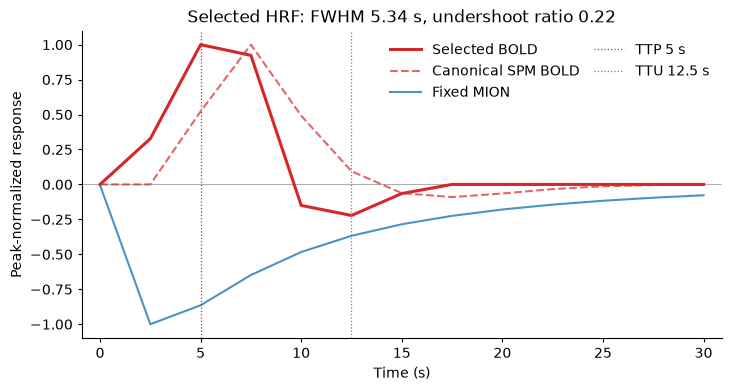

In [2]:
selected_metrics = hrf_shape_metrics(bold, tr)
print("Requested selected HRF")
print(
    f"  TTP={time_to_peak:g} s, FWHM={positive_fwhm:g} s, "
    f"TTU={time_to_undershoot:g} s, undershoot ratio={undershoot_ratio:g}"
)
print("Realized at the selected TR")
print(
    f"  TTP={selected_metrics['time_to_peak']:g} s, "
    f"FWHM={selected_metrics['positive_fwhm']:.2f} s, "
    f"TTU={selected_metrics['time_to_undershoot']:g} s, "
    f"undershoot ratio={selected_metrics['undershoot_ratio']:.2f}"
)
fig = plot_hrf_shapes(bold, canonical_bold, mion, tr=tr)
display(fig)

## The simulated movie

Each run contains three kinds of neural signal, which are mixed into voxels, convolved with that species' HRF, and z-scored:

- `n_shared` signals are the movie, identical in both species.
- `n_group` signals are shared by the subjects of one species and differ between species.
- `n_idio` signals are private to each subject.

Each voxel mixes `n_signals_per_voxel` of these signals, and the mixture stays the same across runs, as a real voxel keeps its tuning. Each signal is a normalized average spike rate: an independent Uniform(0, 1) draw at every TR.

200 TRs per run = 500 seconds


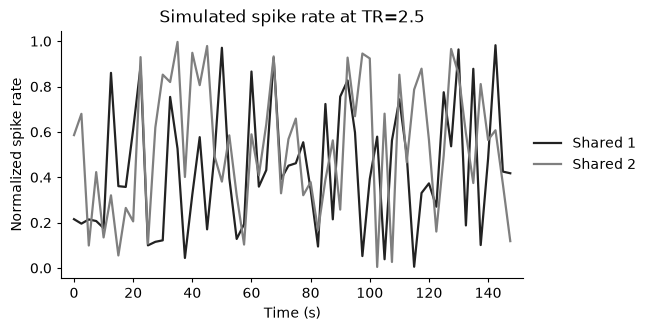

In [3]:
n_shared = 2
n_group = 2
n_idio = 2
n_subjects = 2  # per species
n_signals_per_voxel = 3
n_runs = 5
n_voxels = 50  # per subject
maxiter = 100  # BFGS iteration limit; both learned methods converge well before it

print(f"{n_tr} TRs per run = {n_tr * tr:g} seconds")
simulation = simulate_movie(
    bold, mion,
    n_tr=n_tr, tr=tr, n_runs=n_runs, n_subjects=n_subjects, n_voxels=n_voxels,
    n_shared=n_shared, n_group=n_group, n_idio=n_idio,
    n_signals_per_voxel=n_signals_per_voxel, rng=seed,
)
fig = plot_neural(simulation.neural, simulation.run_index, tr)
display(fig)

## Five ways to prepare the data

| Method | Temporal preparation | Shared space |
|---|---|---|
| **Canonical double convolution** | convolve MION with canonical SPM BOLD and BOLD with the fixed MION HRF | fit on the training runs |
| **Oracle double convolution** | convolve MION with the selected ground-truth BOLD HRF and BOLD with the fixed MION HRF | fit on the training runs |
| **MVTA** | convolve MION with a kernel learned by minimizing between-species disparity *in an SRM shared space, rotated and weighted toward BOLD–MION correlation* | fit on the training runs |
| **No multiview** | convolve MION with a kernel learned from disparity between *voxel averages*, without a shared space | fit on the training runs |
| **No alignment** | leave MION and BOLD unchanged | fit on the training runs |

Every method then goes through the same decoding step. The oracle is intentionally privileged and measures the best case for double convolution when the generating HRF is known. The canonical version is the realistic fixed-HRF comparison under shape variability.

## Learn the kernels

One kernel is learned per held-out run for each of the two learned methods (MVTA and no multiview). A kernel never sees the run it is later tested on.

As in the proof-of-principle notebook, each kernel is learned with BFGS, starting from a flat kernel whose weights sum to one. Only the loss differs. MVTA fits an SRM shared space to the BOLD and transformed MION subjects for every candidate kernel, rotates and weights the scores toward BOLD–MION correlation, and measures the between-species disparity there. `kernel_n_components` sets that SRM rank. No multiview measures disparity between each subject's voxel average. A fold prints a message only if BFGS stops at `maxiter` before converging.

In [4]:
common = dict(
    kernel_length=kernel_length,
    n_components=kernel_n_components,
    bold_hrf=bold, mion_hrf=mion, maxiter=maxiter,
)
print("MVTA")
mvta_kernels = learn_kernels(
    simulation.bold, simulation.mion, simulation.run_index,
    objective="multiview", verbose=True, **common,
)
print("No multiview")
voxel_average_kernels = learn_kernels(
    simulation.bold, simulation.mion, simulation.run_index,
    objective="voxel_average", verbose=True, **common,
)

MVTA
Fold 1/5: holding out run 0


Fold 2/5: holding out run 1


Fold 3/5: holding out run 2


Fold 4/5: holding out run 3


Fold 5/5: holding out run 4


No multiview
Fold 1/5: holding out run 0


Fold 2/5: holding out run 1


Fold 3/5: holding out run 2


Fold 4/5: holding out run 3


Fold 5/5: holding out run 4


## Decode

For each held-out run:

1. Apply that method's temporal preparation. Canonical and oracle double convolution differ only in which BOLD HRF is applied to MION; both apply the fixed MION HRF to BOLD. The learned methods convolve MION only, and no alignment leaves both species unchanged.
2. Fit the SED shared space on the other runs, using the prepared BOLD and MION subjects together. This is SRM with `sed_n_components` components, separate from the SRM used to learn the kernels. It can have more components than there are shared signals, so some components carry signal that is not shared between species.
3. With `filter_shared`, rotate the shared space toward the directions where BOLD and MION agree, and weight each direction by how far that agreement exceeds chance:
   - One training run is set aside as a calibration run, and SRM is fit on the remaining training runs. The calibration run is projected into that space, and the BOLD–MION correlation matrix of its components is decomposed into paired BOLD and MION directions, ordered by how strongly they correlate.
   - Chance is estimated by circularly shifting the MION series in time, which breaks the alignment between species while keeping each series' temporal structure. A direction keeps a positive weight only if its correlation exceeds the 95th percentile of the strongest correlation found across 20 such shifts.
   - The filter is estimated on the calibration run rather than on the runs SRM was fit to, because SRM's fit inflates the correlations on its own training data. Each training run takes a turn as the calibration run.
4. Project the held-out run into the shared space (rotated and weighted, with the filter).
5. Decode in both directions. For every `win_size`-TR window in a MION subject, find the window in the mean BOLD time course with the highest correlation; likewise, match every BOLD subject's windows against the mean MION time course. Windows that overlap the correct window are excluded, apart from the correct window itself. With the filter, the window correlations are averaged over calibration runs before the best match is chosen. The match counts when it picks the same time.

Accuracy is the fraction of correct matches minus chance. It is averaged over subjects within each direction, and then over the two directions, so neither species dominates when the groups differ in size. The printout reports how many directions passed the null; the simulation has `n_shared` shared signals, so it should be close to that.

In [5]:
results = decode_methods(
    simulation.bold, simulation.mion, simulation.run_index,
    {
        "canonical double convolution": canonical_bold,
        "oracle double convolution": bold,
        "MVTA": mvta_kernels,
        "no multiview": voxel_average_kernels,
        "no alignment": np.array([1.0]),
    },
    bold_kernels={
        "canonical double convolution": mion,
        "oracle double convolution": mion,
    },
    n_components=sed_n_components, win_size=win_size,
    filter_shared=filter_shared, random_state=seed,
)
for label, values in results.items():
    print(f"{label:28s} mean {values.mean():.3f}   runs {np.round(values, 3)}")

SED spatial alignment: SRM, 10 components, with the cross-species filter


Directions above the time-shift null (mean over calibration runs)


  canonical double convolution 1.9 of 10


  oracle double convolution 1.9 of 10


  MVTA                 2.0 of 10


  no multiview         2.0 of 10


  no alignment         1.6 of 10


canonical double convolution mean 0.335   runs [0.286 0.418 0.234 0.349 0.387]
oracle double convolution    mean 0.774   runs [0.689 0.794 0.746 0.768 0.873]
MVTA                         mean 0.930   runs [0.958 0.933 0.886 0.951 0.925]
no multiview                 mean 0.736   runs [0.706 0.853 0.708 0.751 0.66 ]
no alignment                 mean 0.032   runs [0.056 0.034 0.036 0.031 0.005]


## Figure

Bars show the mean across held-out runs and dots show each run. The two learned methods share the kernel length, optimizer, and decoding step; they differ only in the loss used to learn the kernel.

Canonical double convolution always assumes the SPM BOLD HRF. Oracle double convolution uses the selected generating BOLD HRF and therefore provides a deliberately privileged comparison. Both smooth each species through two responses. MVTA instead learns one kernel mapping MION toward BOLD, while no multiview learns the same kind of kernel from voxel averages rather than a shared space.

No alignment leaves hemodynamic timing confounded with the simulated neural response. Performance differences here apply to the selected HRF; the final section repeats the complete comparison across HRF shapes while holding signal composition fixed.

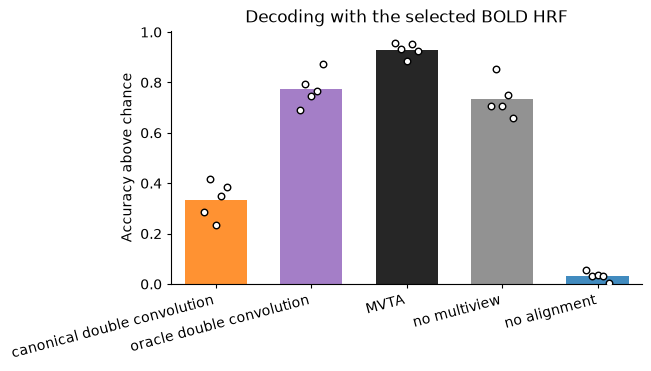

In [6]:
fig = plot_decoding(results, title="Decoding with the selected BOLD HRF")
display(fig)


## Robustness across BOLD HRF shapes

The final comparison selects one signal composition—`balanced`, `shared_rich`, `group_dominant`, or `idio_dominant`—and holds it fixed while changing the generating BOLD HRF. Calling `simulate_movie` with the same seed for every HRF reuses the same latent neural signals and voxel mixing, making comparisons across shapes paired.

The default list changes one descriptor at a time over the empirically informed core ranges, adds a no-undershoot ablation, and includes canonical SPM BOLD. Broader stress scenarios are defined but are not run by default. Edit `robustness_hrf_shapes` to choose the shapes to run. Each dot is the mean across held-out runs for one simulation seed; bars average the seeds.

This section can be slow because every HRF × seed combination learns cross-validated MVTA and voxel-average kernels. Use fewer entries in `robustness_hrf_shapes` or `robustness_seeds` for a pilot.

In [7]:
signal_conditions = {
    "balanced": (2, 2, 2),
    "shared_rich": (4, 1, 1),
    "group_dominant": (1, 4, 1),
    "idio_dominant": (1, 1, 4),
}
robustness_signal_condition = "balanced"
if robustness_signal_condition not in signal_conditions:
    raise ValueError(
        f"robustness_signal_condition must be one of {tuple(signal_conditions)}"
    )
condition_shared, condition_group, condition_idio = signal_conditions[
    robustness_signal_condition
]

# None selects nilearn's canonical SPM HRF. Every other entry contains the
# editable shape targets passed to variable_bold_hrf.
hrf_scenario_specs = {
    "taylor_reference": ("Taylor\nreference", dict(
        time_to_peak=6.1, positive_fwhm=4.1,
        time_to_undershoot=10.8, undershoot_ratio=0.21,
    )),
    "core_early_peak": ("Core early\npeak", dict(
        time_to_peak=4.9, positive_fwhm=4.1,
        time_to_undershoot=10.8, undershoot_ratio=0.21,
    )),
    "core_late_peak": ("Core late\npeak", dict(
        time_to_peak=7.3, positive_fwhm=4.1,
        time_to_undershoot=10.8, undershoot_ratio=0.21,
    )),
    "core_narrow": ("Core narrow\npositive lobe", dict(
        time_to_peak=6.1, positive_fwhm=3.1,
        time_to_undershoot=10.8, undershoot_ratio=0.21,
    )),
    "core_wide": ("Core wide\npositive lobe", dict(
        time_to_peak=6.1, positive_fwhm=5.1,
        time_to_undershoot=10.8, undershoot_ratio=0.21,
    )),
    "core_early_undershoot": ("Core early\nundershoot", dict(
        time_to_peak=6.1, positive_fwhm=4.1,
        time_to_undershoot=8.6, undershoot_ratio=0.21,
    )),
    "core_late_undershoot": ("Core late\nundershoot", dict(
        time_to_peak=6.1, positive_fwhm=4.1,
        time_to_undershoot=13.0, undershoot_ratio=0.21,
    )),
    "core_shallow_undershoot": ("Core shallow\nundershoot", dict(
        time_to_peak=6.1, positive_fwhm=4.1,
        time_to_undershoot=10.8, undershoot_ratio=0.05,
    )),
    "core_deep_undershoot": ("Core deep\nundershoot", dict(
        time_to_peak=6.1, positive_fwhm=4.1,
        time_to_undershoot=10.8, undershoot_ratio=0.40,
    )),
    "no_undershoot": ("No\nundershoot", dict(
        time_to_peak=6.1, positive_fwhm=4.1,
        time_to_undershoot=10.8, undershoot_ratio=0.0,
    )),
    "spm_canonical": ("SPM\ncanonical", None),
    # Broader stress tests: deliberately outside the empirical summary.
    "stress_early_narrow": ("Stress early\nand narrow", dict(
        time_to_peak=4.0, positive_fwhm=2.0,
        time_to_undershoot=7.0, undershoot_ratio=0.05,
    )),
    "stress_late_broad": ("Stress late\nand broad", dict(
        time_to_peak=9.0, positive_fwhm=7.0,
        time_to_undershoot=16.0, undershoot_ratio=0.40,
    )),
    "stress_deep_undershoot": ("Stress deep\nundershoot", dict(
        time_to_peak=6.1, positive_fwhm=4.1,
        time_to_undershoot=10.8, undershoot_ratio=0.60,
    )),
}
robustness_hrf_shapes = [
    "taylor_reference",
    "core_early_peak", "core_late_peak",
    "core_narrow", "core_wide",
    "core_early_undershoot", "core_late_undershoot",
    "core_shallow_undershoot", "core_deep_undershoot",
    "no_undershoot", "spm_canonical",
]
robustness_seeds = [seed, 7, 19]
method_labels = [
    "canonical double convolution", "oracle double convolution",
    "MVTA", "no multiview", "no alignment",
]
robustness_results = {}

for scenario_name in robustness_hrf_shapes:
    display_label, scenario_parameters = hrf_scenario_specs[scenario_name]
    scenario_bold = (
        canonical_bold
        if scenario_parameters is None
        else variable_bold_hrf(tr=tr, time_length=duration, **scenario_parameters)
    )
    metrics = hrf_shape_metrics(scenario_bold, tr)
    print(
        f"{display_label.replace(chr(10), ' ')}: "
        f"TTP={metrics['time_to_peak']:g}, FWHM={metrics['positive_fwhm']:.2f}, "
        f"TTU={metrics['time_to_undershoot']:g}, "
        f"ratio={metrics['undershoot_ratio']:.2f}",
        flush=True,
    )
    robustness_results[display_label] = {
        method: [] for method in method_labels
    }

    for condition_seed in robustness_seeds:
        print(f"  seed {condition_seed}", flush=True)
        is_cached_selected = (
            condition_seed == seed
            and (condition_shared, condition_group, condition_idio)
            == (n_shared, n_group, n_idio)
            and np.array_equal(scenario_bold, bold)
        )
        if is_cached_selected:
            condition_simulation = simulation
            condition_mvta_kernels = mvta_kernels
            condition_voxel_average_kernels = voxel_average_kernels
        else:
            condition_simulation = simulate_movie(
                scenario_bold, mion,
                n_tr=n_tr, tr=tr, n_runs=n_runs, n_subjects=n_subjects,
                n_voxels=n_voxels, n_shared=condition_shared,
                n_group=condition_group, n_idio=condition_idio,
                n_signals_per_voxel=n_signals_per_voxel, rng=condition_seed,
            )
            condition_common = dict(
                kernel_length=kernel_length,
                n_components=kernel_n_components,
                bold_hrf=scenario_bold,
                mion_hrf=mion,
                maxiter=maxiter,
            )
            condition_mvta_kernels = learn_kernels(
                condition_simulation.bold, condition_simulation.mion,
                condition_simulation.run_index,
                objective="multiview", **condition_common,
            )
            condition_voxel_average_kernels = learn_kernels(
                condition_simulation.bold, condition_simulation.mion,
                condition_simulation.run_index,
                objective="voxel_average", **condition_common,
            )

        condition_scores = decode_methods(
            condition_simulation.bold, condition_simulation.mion,
            condition_simulation.run_index,
            {
                "canonical double convolution": canonical_bold,
                "oracle double convolution": scenario_bold,
                "MVTA": condition_mvta_kernels,
                "no multiview": condition_voxel_average_kernels,
                "no alignment": np.array([1.0]),
            },
            bold_kernels={
                "canonical double convolution": mion,
                "oracle double convolution": mion,
            },
            n_components=sed_n_components,
            win_size=win_size,
            filter_shared=filter_shared,
            random_state=condition_seed,
            verbose=False,
        )
        for preparation, values in condition_scores.items():
            robustness_results[display_label][preparation].append(values.mean())

robustness_results = {
    scenario_label: {
        method: np.asarray(values)
        for method, values in methods.items()
    }
    for scenario_label, methods in robustness_results.items()
}
for scenario_label, methods in robustness_results.items():
    advantage = methods["MVTA"].mean() - methods["no multiview"].mean()
    print(
        f"{scenario_label.replace(chr(10), ' '):34s} "
        f"MVTA minus no multiview: {advantage:.3f}"
    )

Taylor reference: TTP=5, FWHM=5.34, TTU=12.5, ratio=0.22


  seed 42


  seed 7


  seed 19


Core early peak: TTP=5, FWHM=4.11, TTU=12.5, ratio=0.17


  seed 42


... (35 outputs left out)

  seed 42


  seed 7


  seed 19


Taylor reference                   MVTA minus no multiview: 0.130
Core early peak                    MVTA minus no multiview: 0.060
Core late peak                     MVTA minus no multiview: 0.157
Core narrow positive lobe          MVTA minus no multiview: 0.118
Core wide positive lobe            MVTA minus no multiview: 0.136
Core early undershoot              MVTA minus no multiview: 0.033
Core late undershoot               MVTA minus no multiview: 0.185
Core shallow undershoot            MVTA minus no multiview: 0.140
Core deep undershoot               MVTA minus no multiview: 0.154
No undershoot                      MVTA minus no multiview: 0.149
SPM canonical                      MVTA minus no multiview: 0.473


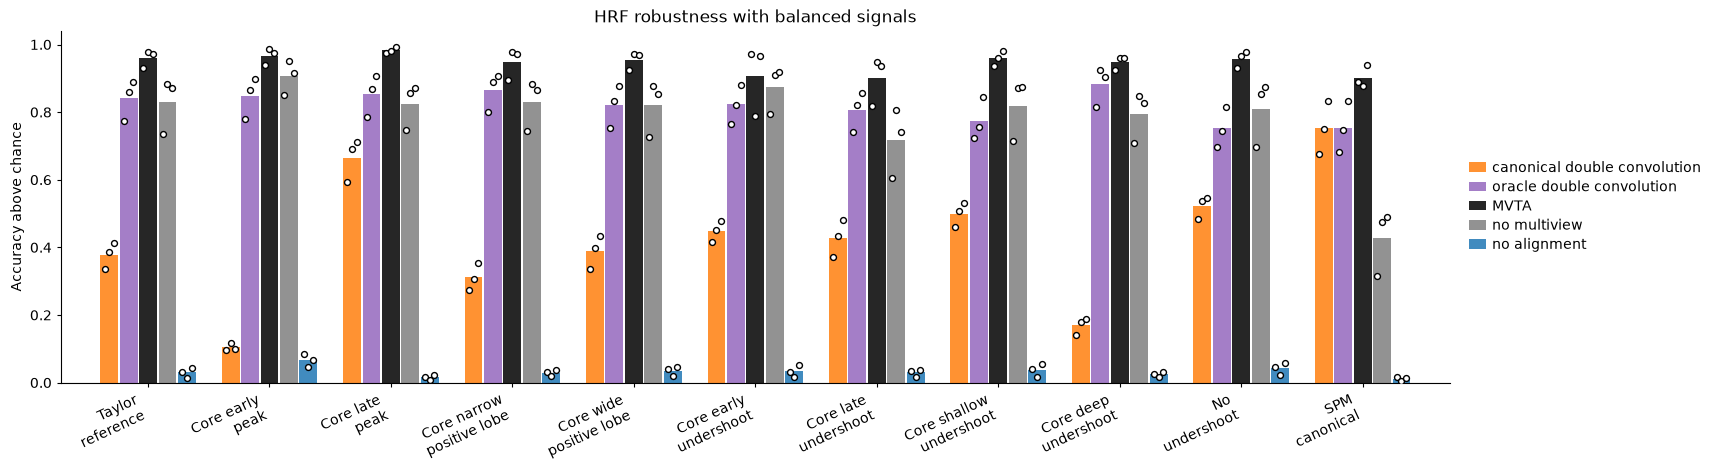

In [8]:
fig = plot_sed_methods(
    robustness_results,
    title=f"HRF robustness with {robustness_signal_condition} signals",
)
ax = fig.axes[0]
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha="right")
ax.legend(
    frameon=False, ncol=1, loc="center left", bbox_to_anchor=(1.01, 0.5),
    borderaxespad=0, labelspacing=0.35, handlelength=1.2, handletextpad=0.45,
)
display(fig)